# 2026-09-17_12-22-54  (experiment 1)  -  freely moving, mouse 4103

Each stage reads only what the previous stage wrote into the analysis folder, and
writes exactly what the next stage reads. Raw data is never modified.

| stage | function | writes |
|---|---|---|
| 0 | `run_layout` | `metadata/channel_layout.*` (what was actually recorded) |
| 1 | `run_sync` | `metadata/timebase.json`, `ttls/TTL_Pin_*.npy` |
| 2 | `run_frames` | `camera_alignment/<view>_frame_times.npy`, `metadata/frame_alignment.json` |
| 3 | `run_units` | `units/units.csv` (label, best channel, depth, DV, region), `units/spike_times.npy` |
| 4 | `run_dlc` | `dlc_alignment/<view>_dlc.npz` (all bodyparts on the canonical clock) |
| 5 | `detect_reaches` | `peak_detection/reaches.npz`, `bouts.npz`, `reaches_meta.json` |
| 6 | `run_reach_peth` | `peth/reach_peth_<subset>.npz/.json/_units.csv`, figures in `qc/` |

Canonical time = seconds since the start of the Neuropixels stream.

In [1]:
# --- setup: find the repo so `import fmpipe` works on any machine -------------
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "fmpipe").is_dir())
sys.path.insert(0, str(REPO))

import numpy as np
import matplotlib.pyplot as plt
from fmpipe import (SessionConfig, run_layout, run_sync, run_frames, run_units, plot_probe_units,
                    run_dlc, load_dlc, detect_reaches, plot_reach_zone,
                    run_reach_peth, plot_reach_peth, plot_peth_depth, plot_stacked_regions, compare_peth,
                    plot_probe_modulation,
                    load_ttl, load_frame_times, read_json)

In [2]:
# --- CONFIG: the only cell you edit ------------------------------------------
cfg = SessionConfig(
    data_root = r"K:/",      # folder that holds the session folders (any drive letter)
    session   = "2026-09-17_12-22-54",
    experiment = 1,                  # Open Ephys experiment number
    video_dir = r"S:\MP4_BACKUP",               # counters CSVs / MP4s
    cameras   = {"paw_angled": dict(pin=0, trigger_hz=200.0),
                 "bottom": dict(pin=1, trigger_hz=120.19)},
    segment   = "longest",                      # or a video number, e.g. 3
    # kilosort4 copies can live on several drives with different curation; the copy with the
    # newest curation is used (missing roots are skipped, so this is safe on any machine)
    ks_search_roots = (r"C:\Users\Shermanlab\Documents\Open Ephys", "Z:/"),
    dlc_h5    = {"paw_angled": r"C:\Users\Shermanlab\Desktop\4103-Kevin-2026-09-22\videos\17092026-3_paw_angledDLC_Resnet50_4103Sep22shuffle3_snapshot_best-130.h5"},                          # view -> DLC .h5 (leave {} until DLC is done)
    dlc_max_tail_missing = {},              # only if acquisition lost the last frames (disk full)
    # Reach zone (pixels, primary camera): a reach = paw_center/digit2 with x > x_min AND y > y_min.
    # The camera moves between days. This was PROPOSED automatically from where the paw ends its
    # reaches after pellet presentation: look at the plot below and edit if it looks wrong.
    reach_zone = {"x_min": 287, "y_min": 318},
)
cfg.init_analysis()
cfg.save()
print("analysis folder:", cfg.analysis_dir)

analysis folder: K:\2026-09-17_12-22-54\Record Node 101\2026-09-17_12-22-54_experiment1_recording1_analysis


Layout (settings.xml): bank runs [(0, 153, 1), (154, 383, 0)], y 1540-5360 um
  Unit depths will be recomputed from the recorded layout.
t0 = NP start = 264.012800 s (OE clock); duration 4592.7 s; NI spans -0.000 -> 4592.7 s
Sync: 4592 pulses paired (NI 4592, NP 4592); slope-1=-5.24e-10, offset=-1.0 us, resid std=25.3 us
  pin 0 paw_cam_trigger         899923 rising edges
  pin 1 second_cam_trigger      540840 rising edges
  pin 2 opto_led                     8 rising edges
  pin 3 sync_1hz                  4592 rising edges
  pin 4 back_beam                   52 rising edges
  pin 5 third_cam_trigger            0 rising edges
  pin 6 pellet_beam                164 rising edges
  pin 7 unused                       0 rising edges



[paw_angled] NI pin 0: 899923 pulses in 4 train(s); 3 counters CSV(s) on 17092026
   train 0: n=       1      11.50->    11.50 s        n/a  ignored (rate/length not a real recording)
   train 1: n=    9166      15.58->    61.38 s   200.0 Hz  TRIGGERED
   train 2: n=       1      87.56->    87.56 s        n/a  ignored (rate/length not a real recording)
   train 3: n=  890755      92.16->  4543.20 s   200.0 Hz  TRIGGERED
   train 1 <-> video 2 (9164 rows), trailing pulses 2
   train 3 <-> video 3 (890753 rows), trailing pulses 2
   counters CSV(s) with no pulse train (recorded outside this OE recording?): videos [1]
   USING video 3: 890753 saved frames of 890753 (0 dropped), 92.16->4543.19 s, interval 4.9969+-0.0089 ms, gaps>15 ms: 0



[bottom] NI pin 1: 540840 pulses in 4 train(s); 3 counters CSV(s) on 17092026
   train 0: n=       1      11.64->    11.64 s        n/a  ignored (rate/length not a real recording)
   train 1: n=    5518      15.58->    61.46 s   120.5 Hz  TRIGGERED
   train 2: n=       1      87.70->    87.70 s        n/a  ignored (rate/length not a real recording)
   train 3: n=  535320      92.15->  4543.28 s   120.5 Hz  TRIGGERED
   train 1 <-> video 2 (5508 rows), trailing pulses 10
   train 3 <-> video 3 (535310 rows), trailing pulses 10
   counters CSV(s) with no pulse train (recorded outside this OE recording?): videos [1]
   USING video 3: 535310 saved frames of 535310 (0 dropped), 92.15->4543.19 s, interval 8.3149+-0.0167 ms, gaps>25 ms: 0
Kilosort/Phy copies (newest curation first):
   K:/                                      curated 2026-10-05 17:19  <-- USED
   C:\Users\Shermanlab\Documents\Open Ephys curated 2026-09-29 10:38
   Z:/                                      curated 2026-09-29 1

Best channel agrees with Phy cluster_info 'ch' for 100.0% of clusters


Labels used from cluster_info.tsv: noise=549, good=199
199 good units in analysis (0 excluded by config)
region  CFA  THAL  VAL  WM
n       107    41   32  19


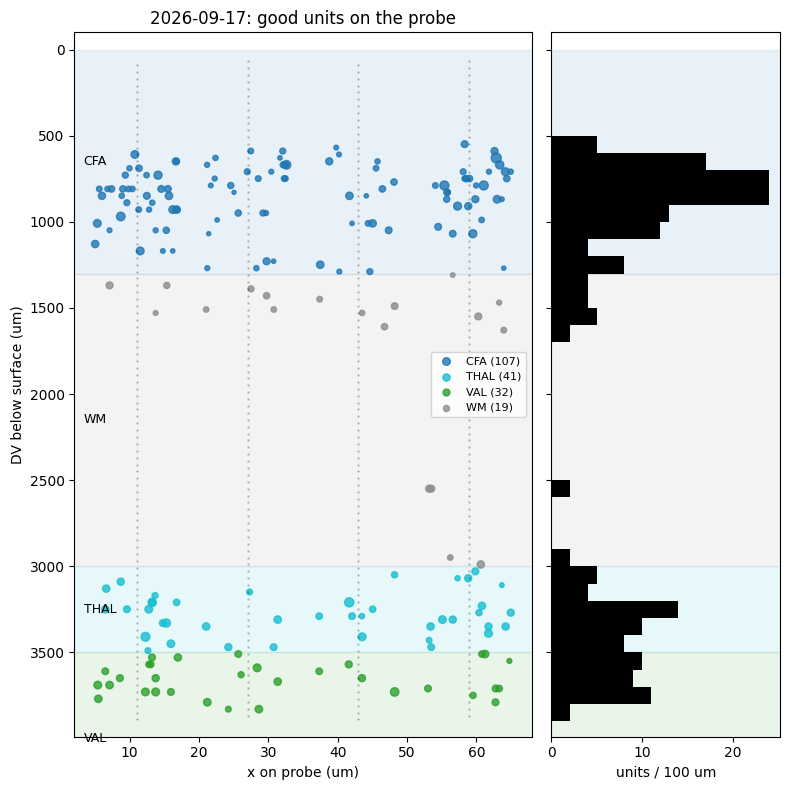

[paw_angled] DLC shuffle3_snapshot_best-130: 890753 rows <-> frames 92.16->4543.19 s
   paw_center  median likelihood 0.147   >=0.5: 27.4%   >=0.9: 3.9%
   digit2      median likelihood 0.125   >=0.5: 26.1%   >=0.9: 3.1%
   nose        median likelihood 0.142   >=0.5: 19.1%   >=0.9: 2.9%
Zone x>287, y>318: 225 reaches in 75 bouts (43 beam-tagged)
  back-beam trials with a bout: 18/52; bout-onset rate inside trial windows 0.35 vs random windows 0.10  (enrichment 3.5x)


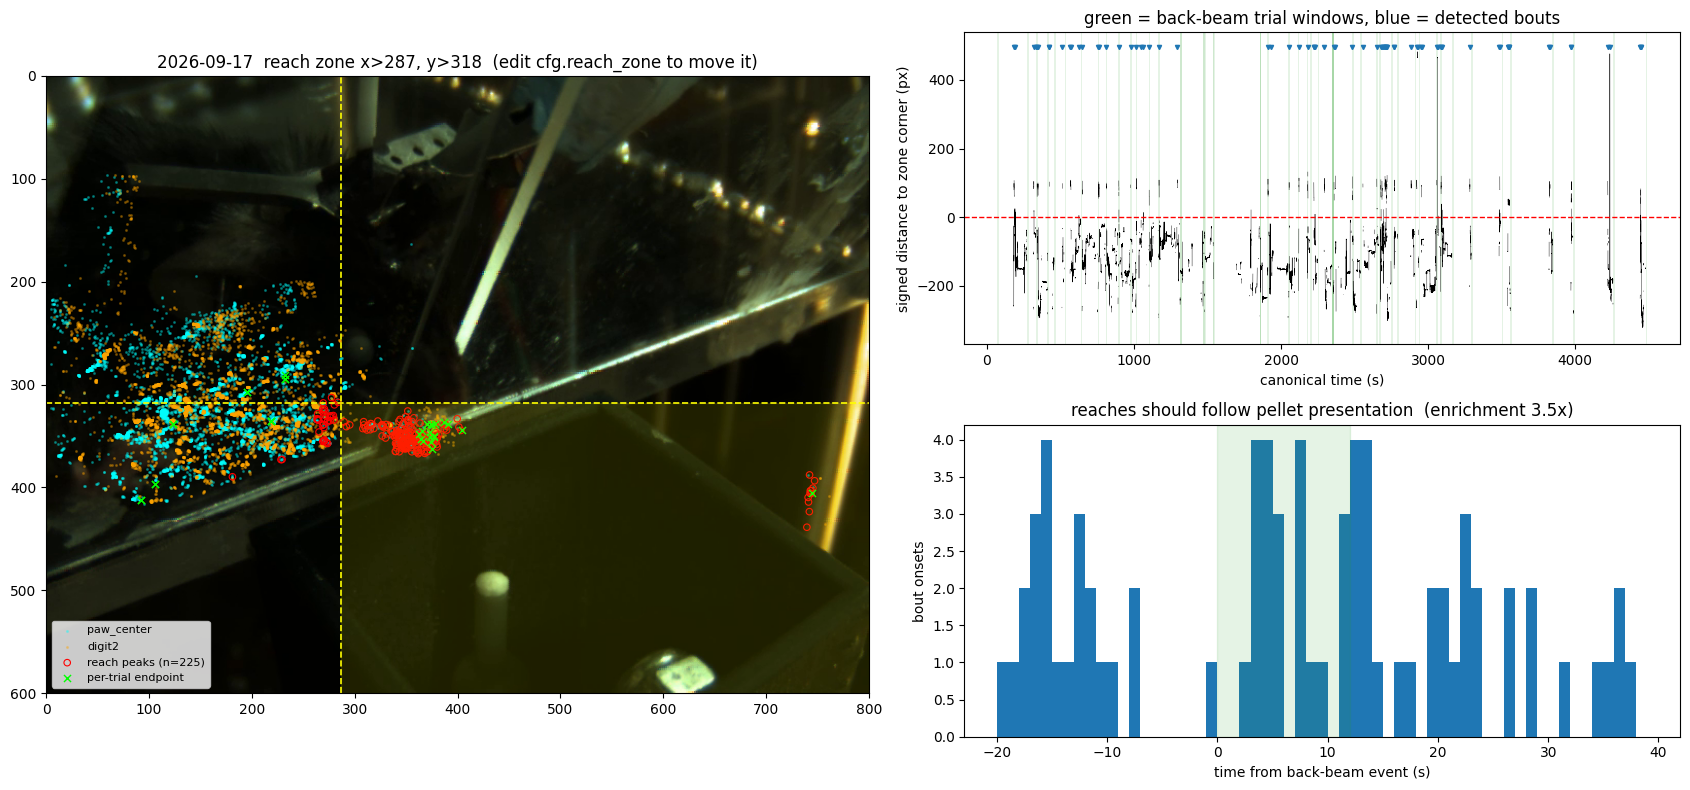

75 events ('all'; window -2.0..+3.0 s, response (-0.5, 2.0)), 180 eligible units ({'CFA': 90, 'THAL': 40, 'VAL': 32, 'WM': 18})


Calibrated Z = 2.75 (shuffled FPR 6.4%);  modulated 126/180
  CFA:  68/90  modulated  (38 excited, 30 suppressed)
   WM:  11/18  modulated  (7 excited, 4 suppressed)
  THAL:  25/40  modulated  (20 excited, 5 suppressed)
  VAL:  22/32  modulated  (12 excited, 10 suppressed)
  THALAMUS:  47/72  modulated  (32 excited, 15 suppressed)


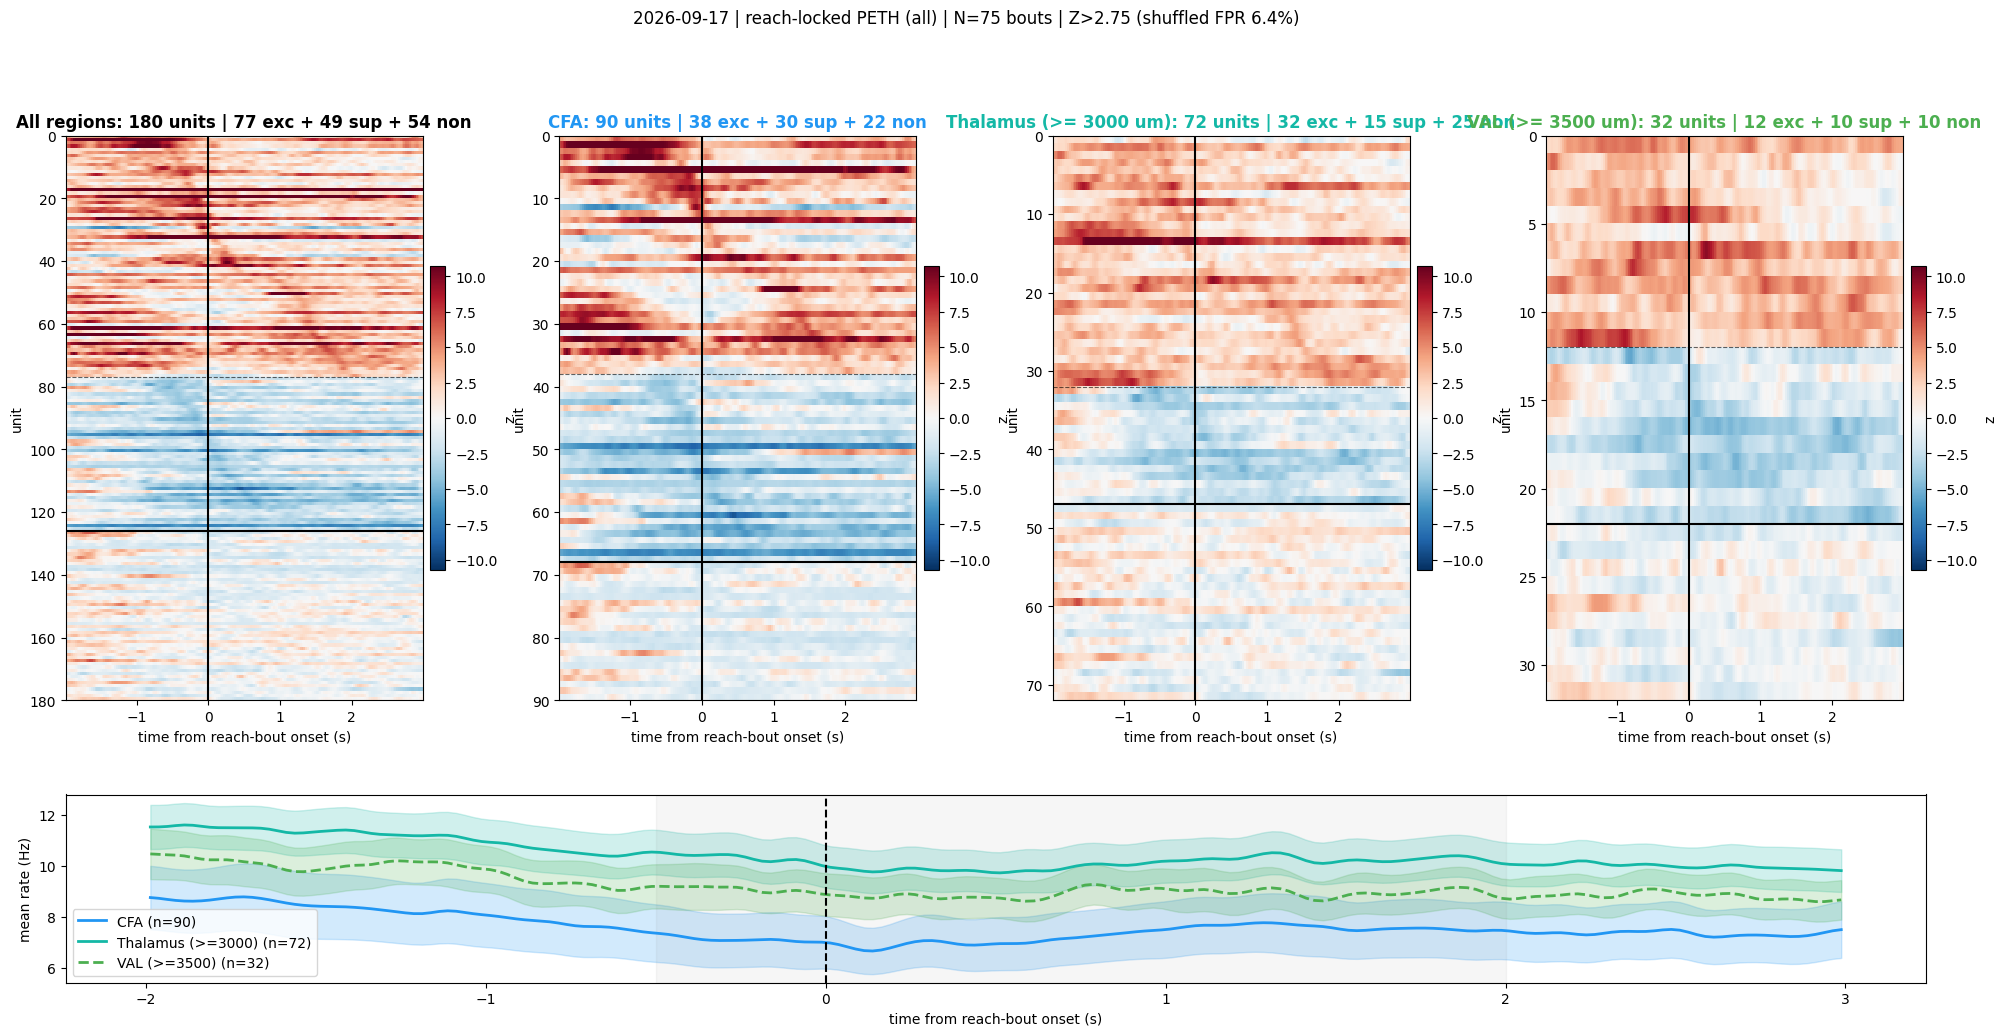

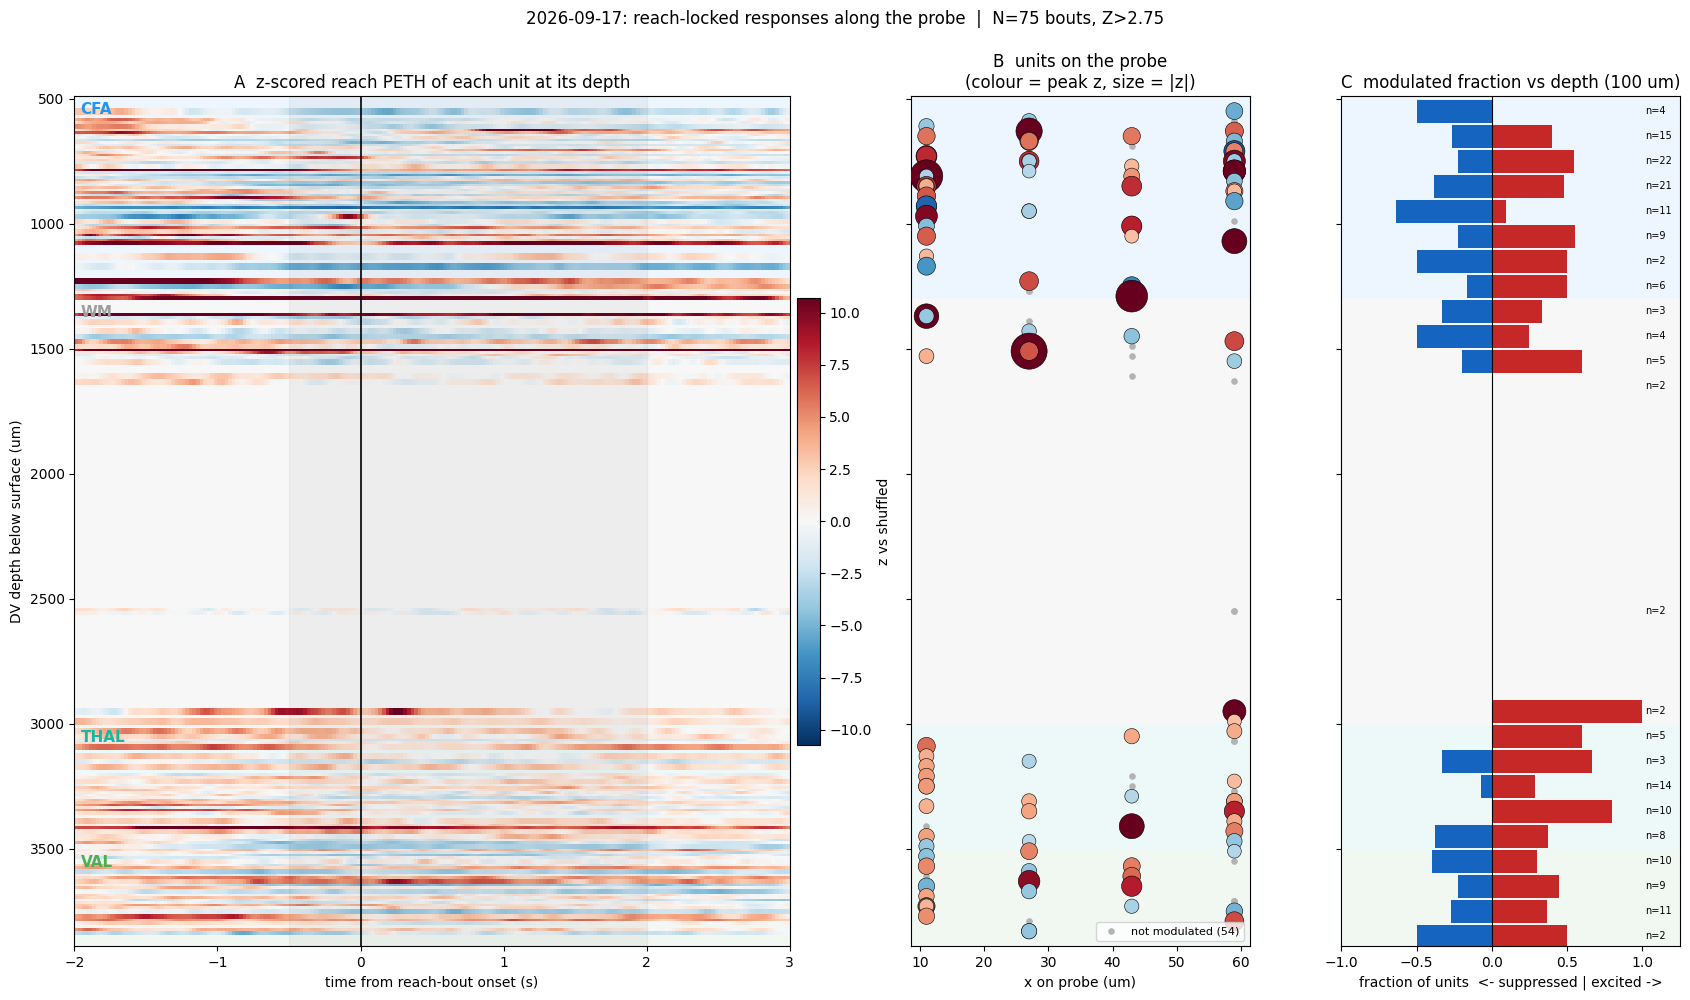

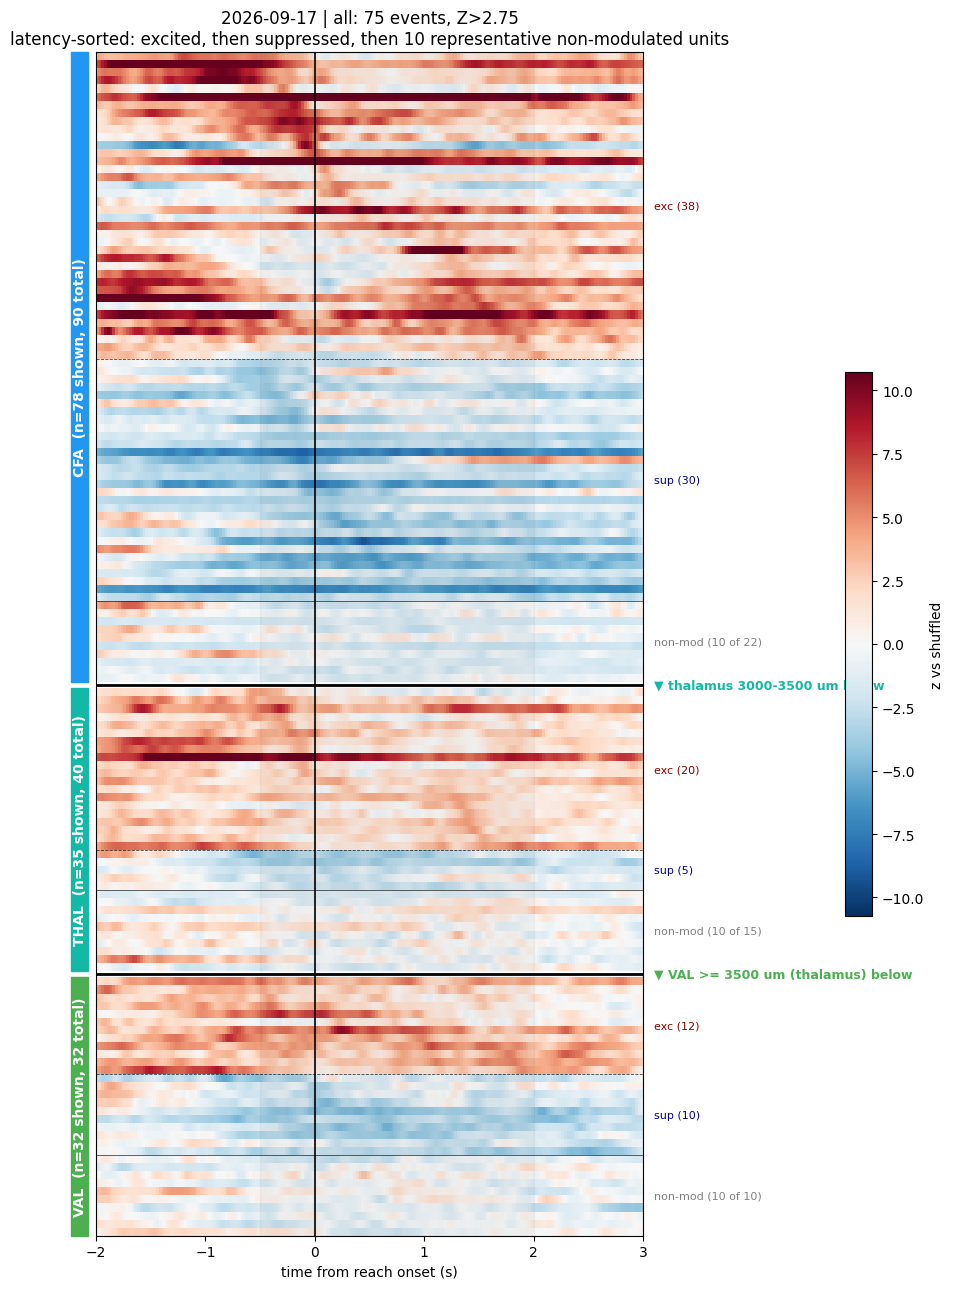

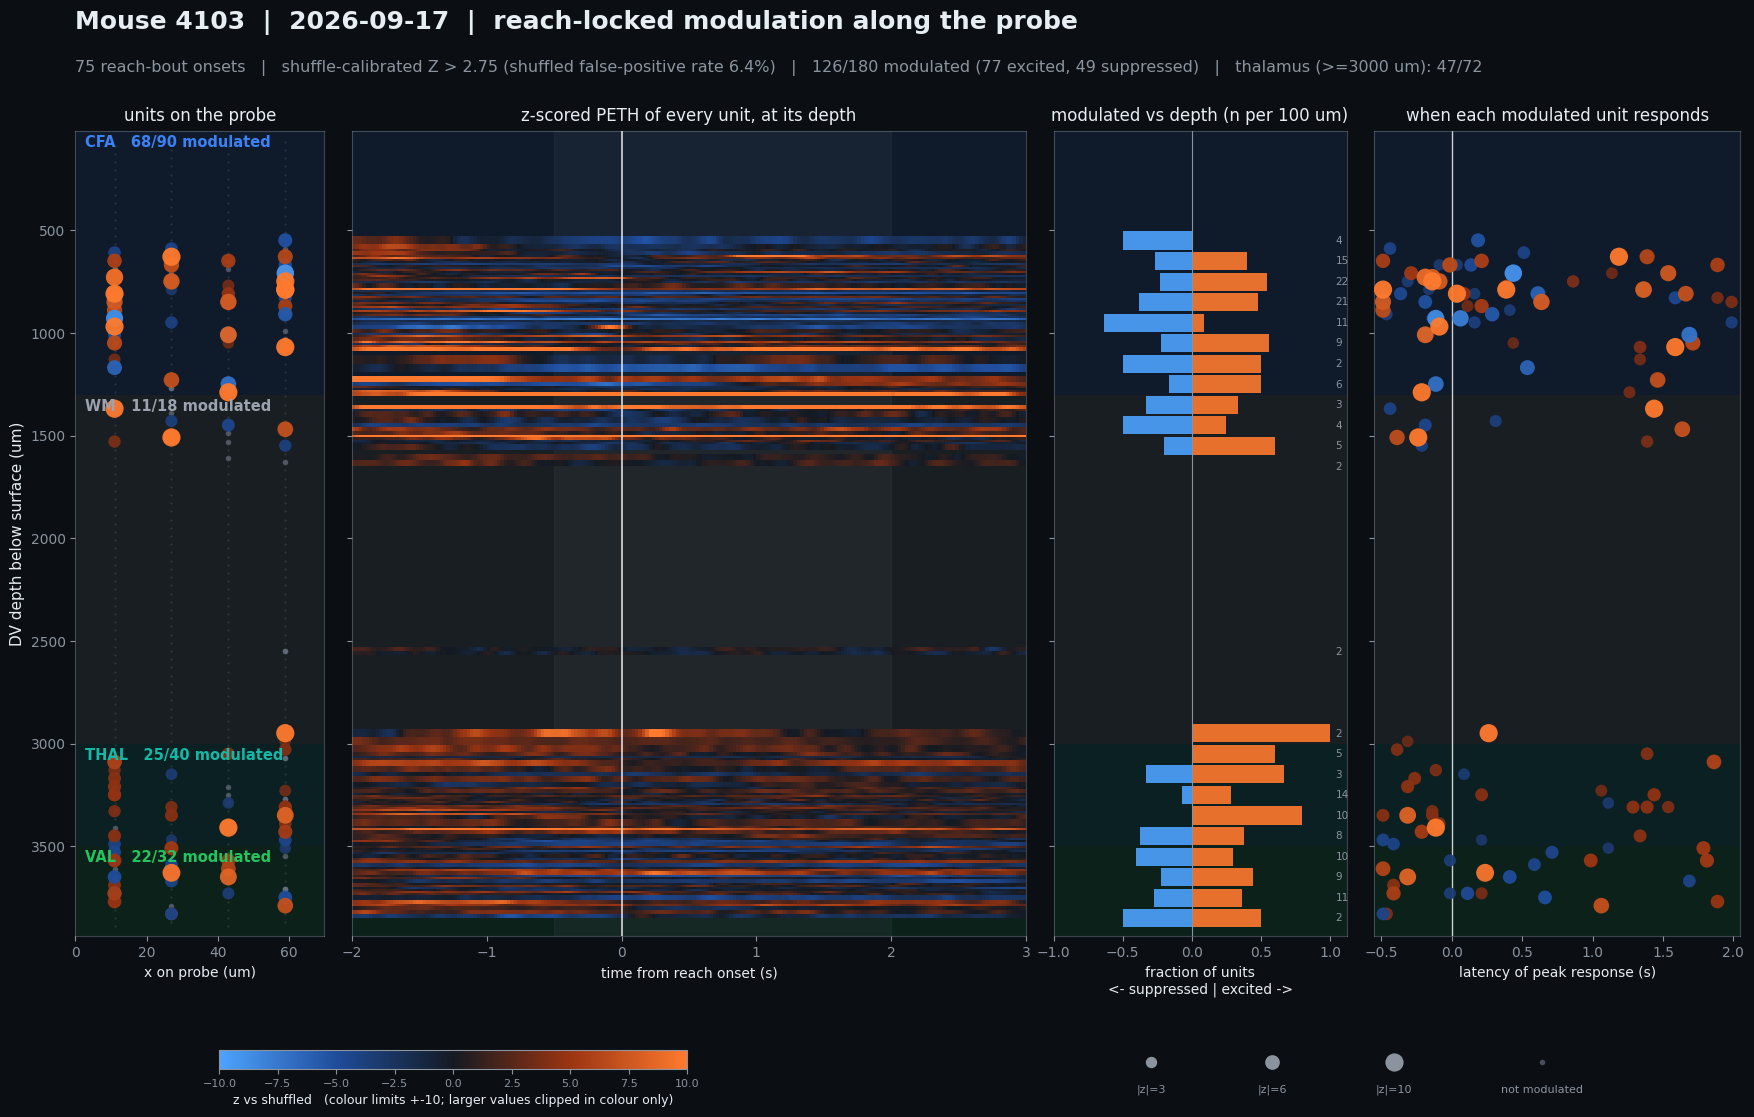

225 events ('all_reaches', in 75 bouts, bout-preserving null; window -1.5..+1.5 s, response (-1.0, 1.0)), 180 eligible units ({'CFA': 90, 'THAL': 40, 'VAL': 32, 'WM': 18})


Calibrated Z = 2.50 (shuffled FPR 7.8%);  modulated 137/180
  CFA:  71/90  modulated  (35 excited, 36 suppressed)
   WM:  12/18  modulated  (7 excited, 5 suppressed)
  THAL:  28/40  modulated  (22 excited, 6 suppressed)
  VAL:  26/32  modulated  (12 excited, 14 suppressed)
  THALAMUS:  54/72  modulated  (34 excited, 20 suppressed)


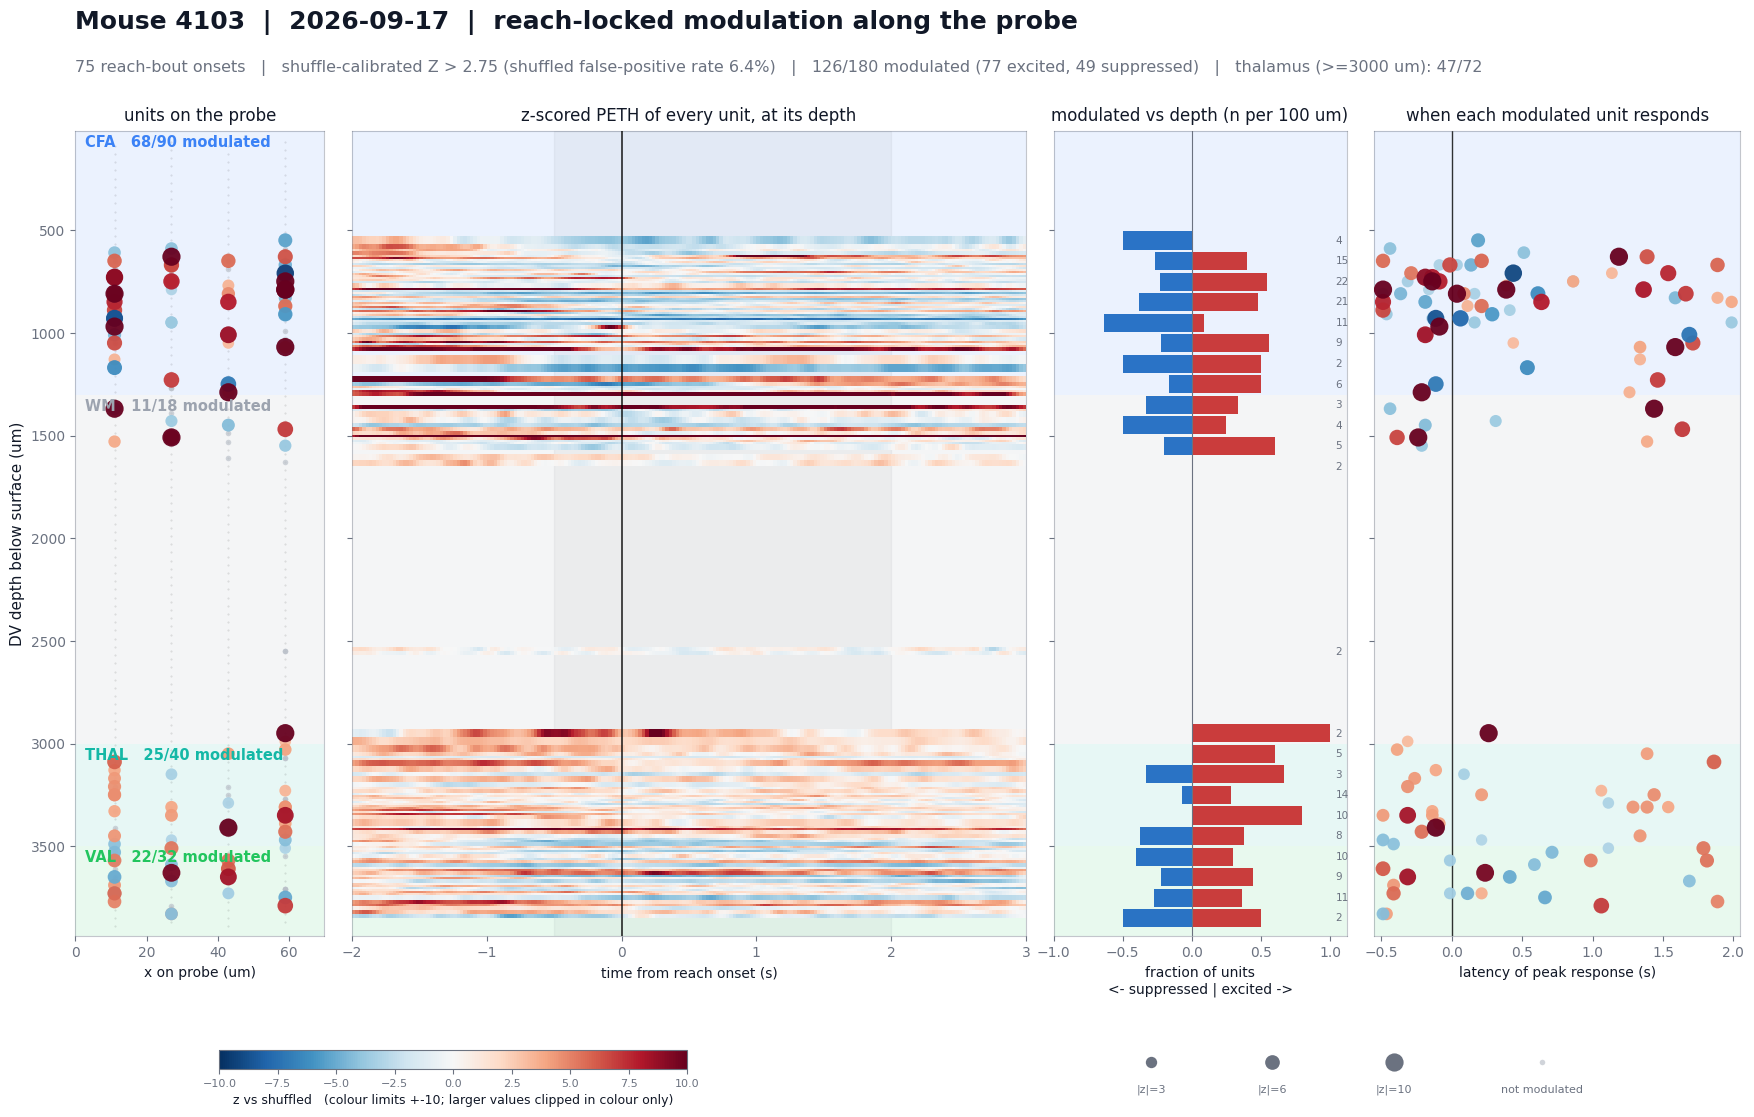

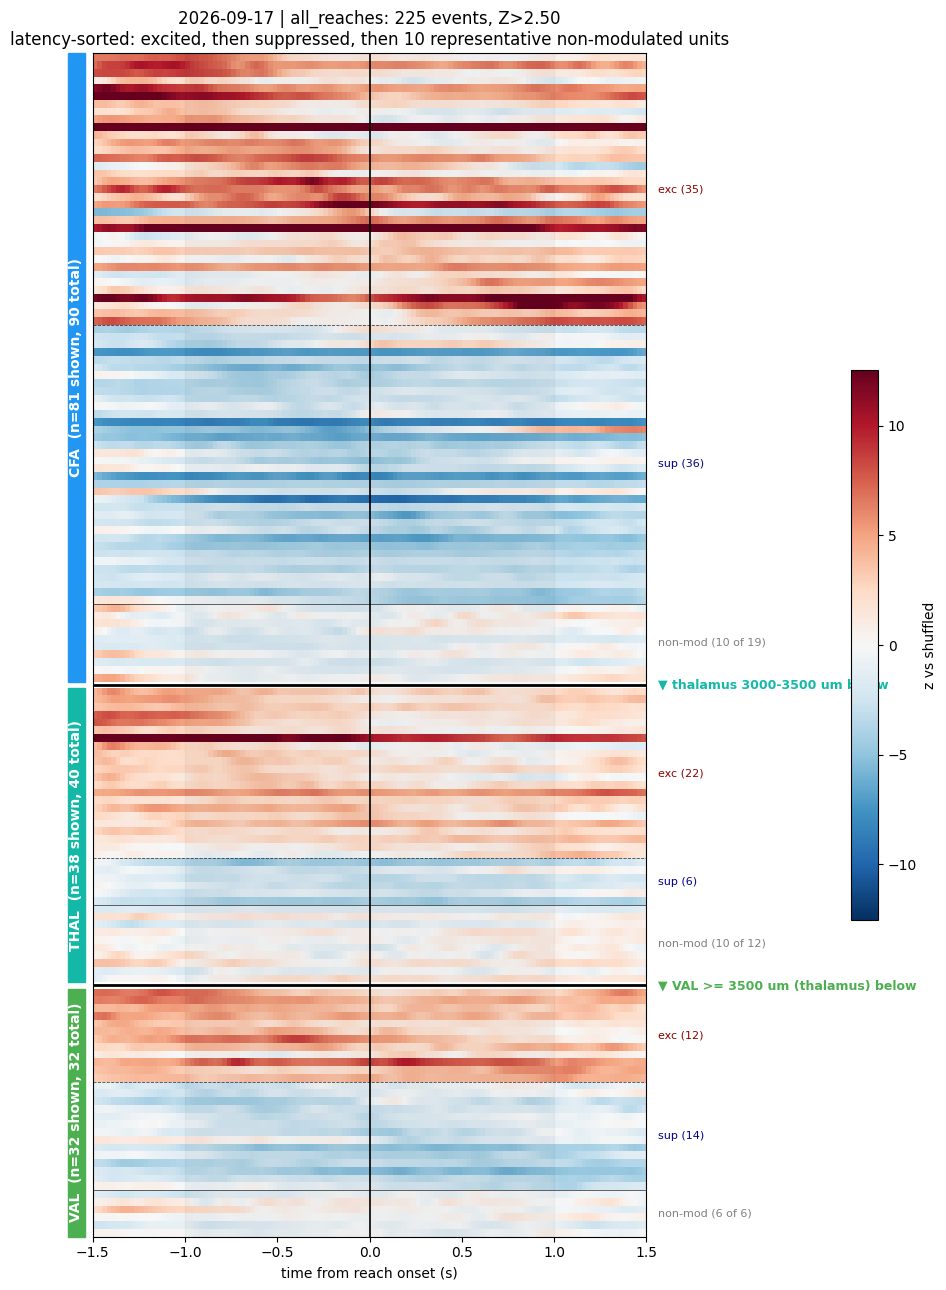

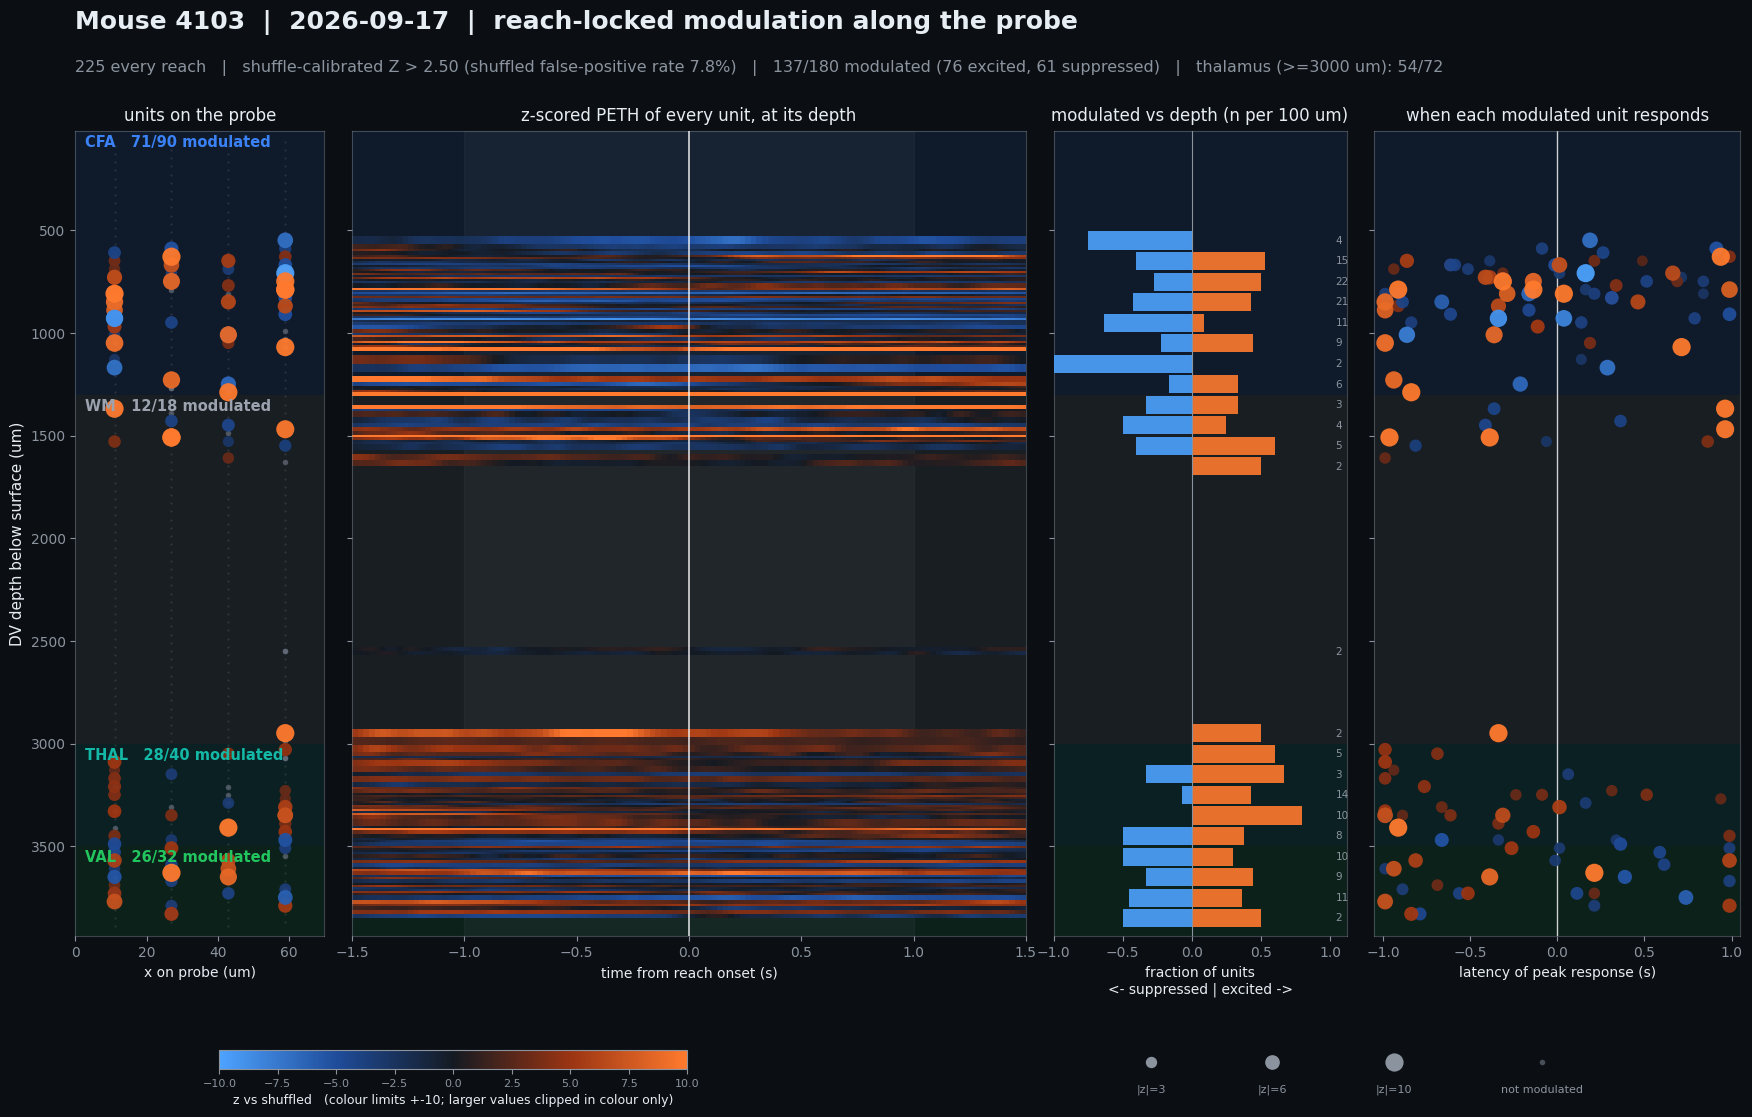

all (75 events, Z>2.75) vs all_reaches (225 events, Z>2.50) on 180 units:
  modulated in both 117, only all 9, only all_reaches 20, neither 34;  same direction in 116/117 of the shared ones;  peak-z correlation r=0.96


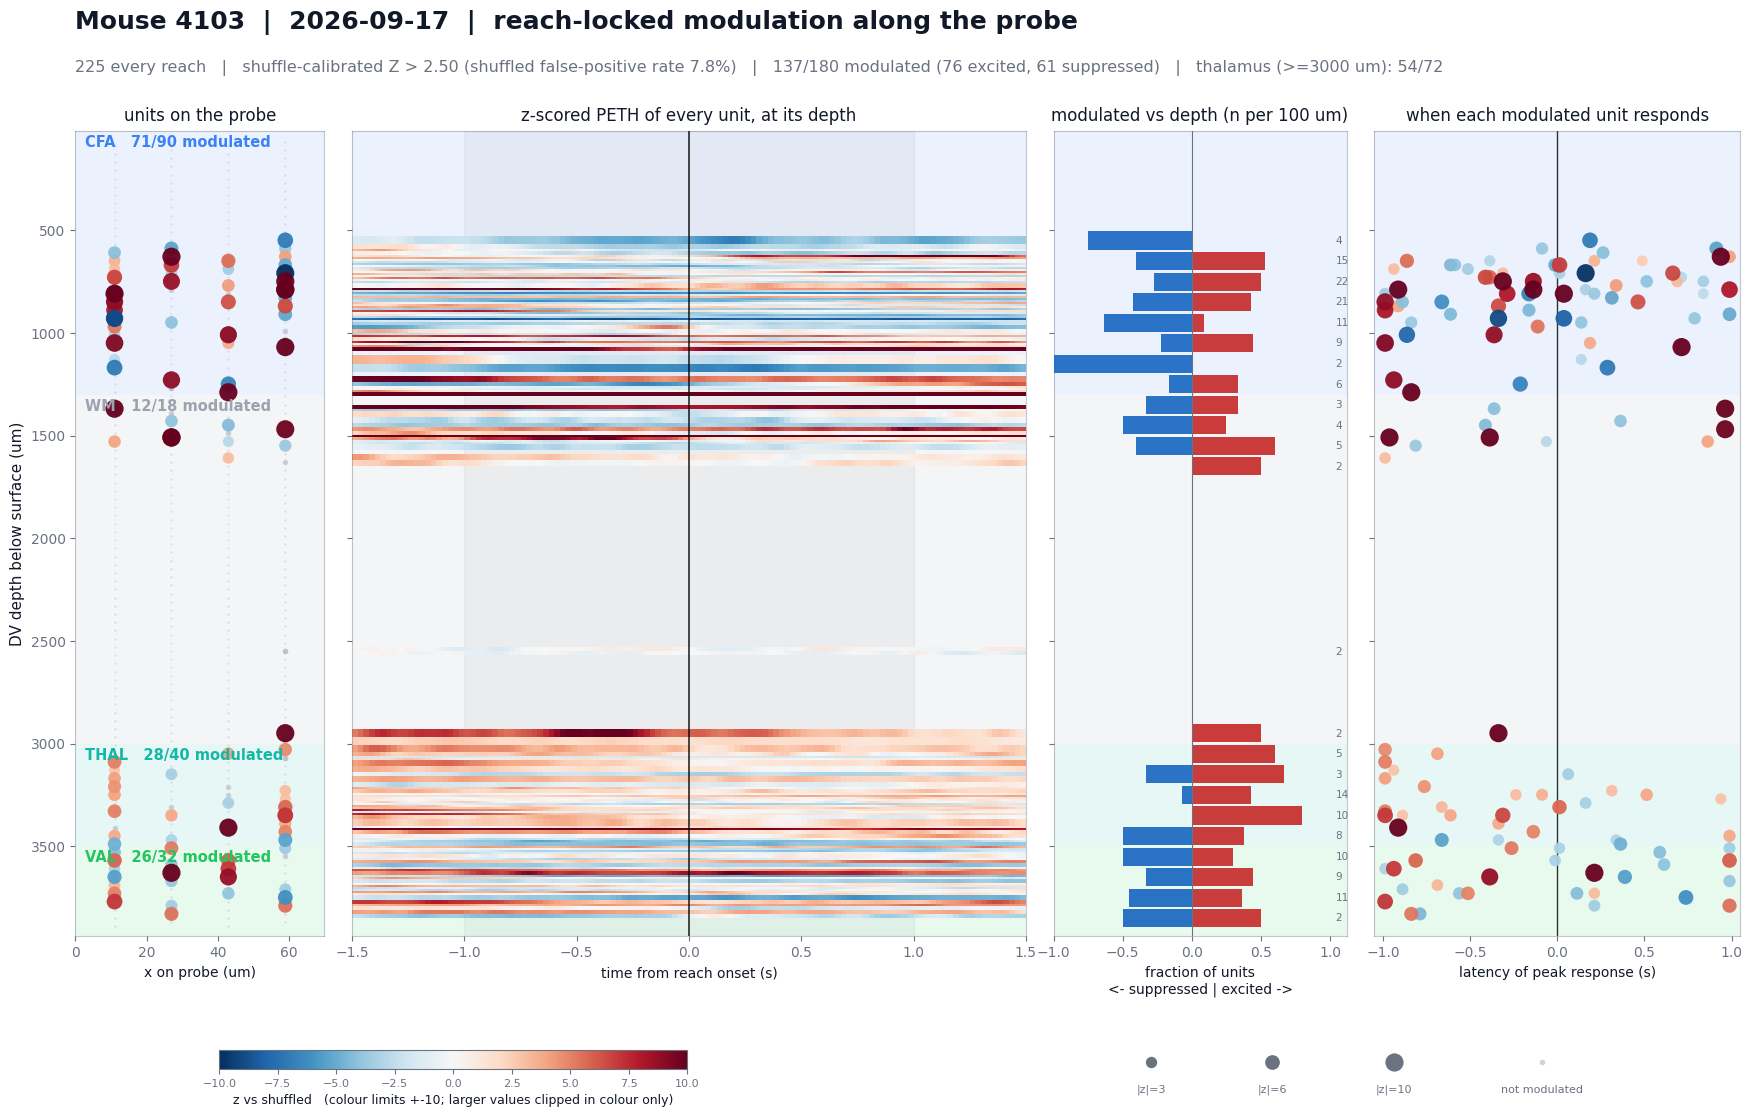

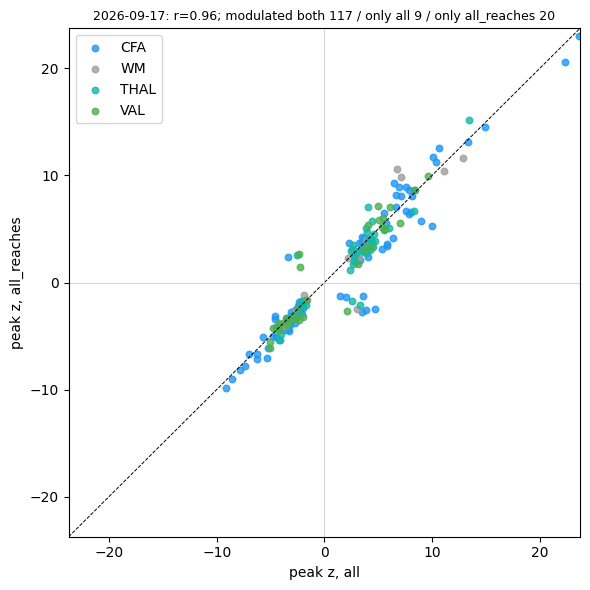

In [3]:
# --- stages 0-3 ----------------------------------------------------------------
run_layout(cfg)
run_sync(cfg)
run_frames(cfg)
units = run_units(cfg)
plot_probe_units(cfg, units); plt.show()
run_dlc(cfg)

# --- stage 5: reaches ----------------------------------------------------------
if cfg.reach_zone:
    detect_reaches(cfg)
    plot_reach_zone(cfg); plt.show()

    # --- stage 6: reach-locked PETH (shuffle-calibrated), by region and by depth ---------
    res = run_reach_peth(cfg, subset="all")      # or "first_in_trial" / "in_trial"
    plot_reach_peth(cfg, res); plt.show()
    plot_peth_depth(cfg, res); plt.show()
    plot_stacked_regions(cfg, res, "all"); plt.show()   # CFA on top, VAL below, latency-sorted
    plot_probe_modulation(cfg, res, "all", theme="dark"); plt.show()      # responses along the probe
    plot_probe_modulation(cfg, res, "all", theme="light")

    # --- robustness: EVERY reach (not only the first of a bout), window -1.5..+1.5 s, response -1..+1 s.
    # The null keeps each bout's internal reach timing and randomises only where bouts fall.
    res_all = run_reach_peth(cfg, subset="all_reaches")
    plot_stacked_regions(cfg, res_all, "all_reaches"); plt.show()
    plot_probe_modulation(cfg, res_all, "all_reaches", theme="dark"); plt.show()
    plot_probe_modulation(cfg, res_all, "all_reaches", theme="light")
    compare_peth(cfg, "all", "all_reaches"); plt.show()

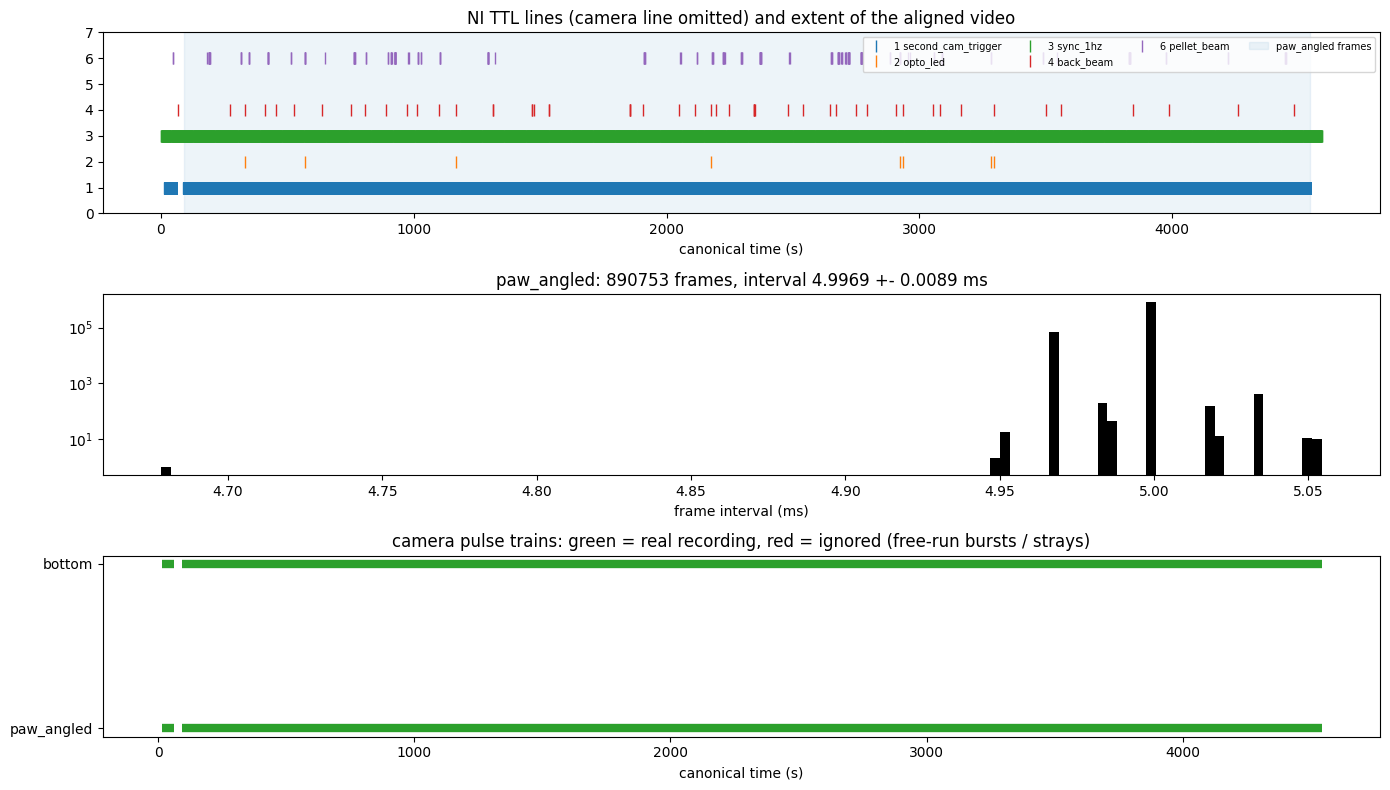

sync residual std: 25.3 us
recording duration: 4592.7 s
paw_angled: video 3, 890753 frames, 0 dropped
bottom: video 3, 535310 frames, 0 dropped


In [4]:
# --- sanity overview -----------------------------------------------------------
tb = read_json(cfg.analysis_dir / "metadata" / "timebase.json")
fa = read_json(cfg.analysis_dir / "metadata" / "frame_alignment.json")
view = cfg.primary_view
ft = load_frame_times(cfg, view)

fig, ax = plt.subplots(3, 1, figsize=(14, 8))
for pin in range(8):
    t = load_ttl(cfg, pin)
    if len(t) and pin != cfg.cameras.get(view, {}).get("pin"):
        ax[0].plot(t, np.full_like(t, pin), "|", ms=8, label=f"{pin} {cfg.pin_labels[pin]}")
ax[0].axvspan(ft[0], ft[-1], color="tab:blue", alpha=0.08, label=f"{view} frames")
ax[0].set_yticks(range(8)); ax[0].set_xlabel("canonical time (s)")
ax[0].set_title("NI TTL lines (camera line omitted) and extent of the aligned video")
ax[0].legend(fontsize=7, ncol=4, loc="upper right")

iv = np.diff(ft) * 1e3
ax[1].hist(iv, bins=np.linspace(iv.min(), min(iv.max(), 10), 120), color="k")
ax[1].set_yscale("log"); ax[1].set_xlabel("frame interval (ms)")
ax[1].set_title(f"{view}: {len(ft)} frames, interval {iv.mean():.4f} +- {iv.std():.4f} ms")

for v, r in fa.items():
    for i, tr in enumerate(r["trains"]):
        ax[2].plot([tr["t_start"], tr["t_end"]], [list(fa).index(v)] * 2, lw=6,
                   color="tab:green" if tr["triggered"] else "tab:red", solid_capstyle="butt")
ax[2].set_yticks(range(len(fa))); ax[2].set_yticklabels(list(fa))
ax[2].set_xlabel("canonical time (s)")
ax[2].set_title("camera pulse trains: green = real recording, red = ignored (free-run bursts / strays)")
plt.tight_layout(); plt.show()

print("sync residual std: %.1f us" % (tb["sync"]["resid_std_s"] * 1e6))
print("recording duration: %.1f s" % tb["recording_duration_s"])
for v, r in fa.items():
    print(f"{v}: video {r['video']}, {r['n_saved']} frames, {r['n_dropped']} dropped")